# Building Energy Efficiency - Regression Project
## Notebook 1: Problem Definition -> Data -> EDA -> Cleaning -> Feature Engineering -> Splitting

**How to read this notebook.** Every step has a short *What / Why* explanation written for someone new to machine learning. Unfamiliar words are explained in the **Glossary** at the bottom.

**ML process steps covered here** (numbering follows the instructor's handout):
1. Problem Definition
2. Data Collection
3. Data Exploration and Preparation (EDA, cleaning, feature engineering, splitting)

---
# Step 1 - Problem Definition

### The real-world problem
Heating and cooling account for a large share of the energy a building uses. An architect who is still *designing* a building would like to know quickly how much heating and cooling it will need, so they can compare design options (more glass? a more compact shape?). Detailed energy simulations give the answer but take time for every single option.

### The ML question
> Given a handful of design parameters (shape, surface areas, height, orientation, amount and placement of windows), can we predict the building's **heating load** and **cooling load**?

* **Heating load** = the heat the building needs per year to stay warm; **cooling load** = the cooling it needs to stay cool. Both are expressed in kWh per m² per year.

### What type of ML problem is this?
* We know the correct answer for every example building, so this is **supervised learning**.
* The answer is a **number on a continuous scale** (not a category), so this is **regression**. (Our first project predicted a category, which is *classification*.)
* There are **two targets**, so we build one model for heating and one for cooling.

### Success criteria (how we will judge the models)
In regression we measure *how far off* the predictions are:

| Metric | Plain-English meaning |
|---|---|
| **MAE** (mean absolute error) | On average, how many load units are we off? Easy to read. |
| **MSE** (mean squared error) | Average of the *squared* errors. Punishes big mistakes heavily, but its unit is "load squared". |
| **RMSE** (root mean squared error) | The square root of MSE, so it is back in load units. Like MAE, but big mistakes count more. |
| **R²** (R-squared) | The share of the ups and downs in the loads that the model explains. 1.0 = perfect, 0.0 = no better than always guessing the average. |

**Targets set before looking at any results:** **R² of at least 0.95** and **RMSE of at most 2.0** for *both* targets (the loads vary with a standard deviation of about 10, so an RMSE of 2 is an error of roughly a fifth of the normal variation).

We will also run a tougher *stress test* later (how well do the models predict for building **shapes they have never seen**?), because that is what an architect with a brand-new design really needs.

In [1]:
# A tiny example so the four metrics are not just words: 3 buildings, actual vs predicted heating load
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

actual = np.array([10.0, 20.0, 30.0])
predicted = np.array([12.0, 18.0, 33.0])
print("errors (predicted - actual):", predicted - actual)
print("MAE  =", round(mean_absolute_error(actual, predicted), 2), "  <- average of |errors| = (2+2+3)/3")
print("MSE  =", round(mean_squared_error(actual, predicted), 2), "  <- average of squared errors = (4+4+9)/3")
print("RMSE =", round(mean_squared_error(actual, predicted) ** 0.5, 2), "  <- square root of MSE")
print("R2   =", round(r2_score(actual, predicted), 3), "  <- 1 means perfect; 0 means 'no better than the average'")

errors (predicted - actual): [ 2. -2.  3.]
MAE  = 2.33   <- average of |errors| = (2+2+3)/3
MSE  = 5.67   <- average of squared errors = (4+4+9)/3
RMSE = 2.38   <- square root of MSE
R2   = 0.915   <- 1 means perfect; 0 means 'no better than the average'


---
# Step 2 - Data Collection

We use the public **Energy Efficiency** dataset from the UCI Machine Learning Repository (ID 242, licence CC BY 4.0).
Source: Tsanas & Xifara (2012), *Energy and Buildings* 49, 560-567; DOI 10.24432/C51307.

The data is **simulated**, not measured: the authors used building-energy software (Ecotect) to simulate the heating and cooling needs of **768 residential building designs**. Each row is one simulated building.

The file `data/energy_efficiency.csv` was downloaded by `00_download_data.py`, so every notebook uses exactly the same data.

In [2]:
import json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50, "display.width", 200)

SEED = 42                                   # fixed random seed so results are repeatable
DATA, FIG = Path("data"), Path("figures")
FIG.mkdir(exist_ok=True)
HEAT, COOL = "#EC4259", "#2A7CBD"           # one colour per target in every chart
TARGETS = ["heating_load", "cooling_load"]

def save(name):
    plt.tight_layout()
    plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight")

df = pd.read_csv(DATA / "energy_efficiency.csv")
print("Rows, columns:", df.shape)
df.head()

Rows, columns: (768, 10)


,relative_compactness,surface_area,wall_area,roof_area,overall_height,orientation,glazing_area,glazing_area_distribution,heating_load,cooling_load
0,0.98,514.5,294.0,110.25,7.0,2,0.0,0,15.55,21.33
1,0.98,514.5,294.0,110.25,7.0,3,0.0,0,15.55,21.33
2,0.98,514.5,294.0,110.25,7.0,4,0.0,0,15.55,21.33
3,0.98,514.5,294.0,110.25,7.0,5,0.0,0,15.55,21.33
4,0.90,563.5,318.5,122.50,7.0,2,0.0,0,20.84,28.28


**What we see:** 768 buildings and 10 columns: 8 **inputs** (called *features*, written **X**) and 2 **targets** (the things we predict, written **y**).

| Column | Meaning |
|---|---|
| `relative_compactness` | How compact the shape is (higher = more compact) |
| `surface_area` | Total outside surface (m²) |
| `wall_area` | Wall area (m²) |
| `roof_area` | Roof area (m²) |
| `overall_height` | Height of the building (m) |
| `orientation` | Which way the building faces (4 options, coded 2 to 5) |
| `glazing_area` | Share of window area (0%, 10%, 25% or 40%) |
| `glazing_area_distribution` | Where the windows are: 0 = no windows, 1 = spread evenly, 2 to 5 = concentrated on one side |
| `heating_load`, `cooling_load` | **Targets**, in kWh/m² per year |

---
# Step 3 - Data Exploration and Preparation

## 3.1 Exploratory Data Analysis (EDA)
**What:** looking at the data with tables and charts *before* modelling. **Why:** to find problems, understand what drives the loads, and guide every later decision.

### 3.1.1 Basic health check

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   relative_compactness       768 non-null    float64
 1   surface_area               768 non-null    float64
 2   wall_area                  768 non-null    float64
 3   roof_area                  768 non-null    float64
 4   overall_height             768 non-null    float64
 5   orientation                768 non-null    int64  
 6   glazing_area               768 non-null    float64
 7   glazing_area_distribution  768 non-null    int64  
 8   heating_load               768 non-null    float64
 9   cooling_load               768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


In [4]:
print("Missing values in total:", int(df.isna().sum().sum()))
print("Duplicate rows         :", int(df.duplicated().sum()))
df.describe().round(2).T

Missing values in total: 0
Duplicate rows         : 0


,count,mean,std,min,25%,50%,75%,max
relative_compactness,768.0,0.76,0.11,0.62,0.68,0.75,0.83,0.98
surface_area,768.0,671.71,88.09,514.50,606.38,673.75,741.12,808.50
wall_area,768.0,318.50,43.63,245.00,294.00,318.50,343.00,416.50
roof_area,768.0,176.60,45.17,110.25,140.88,183.75,220.50,220.50
overall_height,768.0,5.25,1.75,3.50,3.50,5.25,7.00,7.00
orientation,768.0,3.50,1.12,2.00,2.75,3.50,4.25,5.00
glazing_area,768.0,0.23,0.13,0.00,0.10,0.25,0.40,0.40
glazing_area_distribution,768.0,2.81,1.55,0.00,1.75,3.00,4.00,5.00
heating_load,768.0,22.31,10.09,6.01,12.99,18.95,31.67,43.10
cooling_load,768.0,24.59,9.51,10.90,15.62,22.08,33.13,48.03


No missing values and no duplicate rows. This is **simulated** data, which is why it is so tidy - real measurements usually contain gaps and noise.

### 3.1.2 A hidden structure: the data is a designed grid
Before plotting, count how many different values each input has. A real-world dataset would show many different values; a *designed* one does not.

In [5]:
inputs = ["relative_compactness", "surface_area", "wall_area", "roof_area", "overall_height",
          "orientation", "glazing_area", "glazing_area_distribution"]
print(pd.DataFrame({"distinct values": df[inputs].nunique(), "examples": [sorted(df[c].unique())[:5] for c in inputs]}))

geom = ["relative_compactness", "surface_area", "wall_area", "roof_area", "overall_height"]
print("\nDistinct building geometries (combinations of the first 5 inputs):", len(df[geom].drop_duplicates()))

                           distinct values                             examples
relative_compactness                    12       [0.62, 0.64, 0.66, 0.69, 0.71]
surface_area                            12  [514.5, 563.5, 588.0, 612.5, 637.0]
wall_area                                7  [245.0, 269.5, 294.0, 318.5, 343.0]
roof_area                                4        [110.25, 122.5, 147.0, 220.5]
overall_height                           2                           [3.5, 7.0]
orientation                              4                         [2, 3, 4, 5]
glazing_area                             4                [0.0, 0.1, 0.25, 0.4]
glazing_area_distribution                6                      [0, 1, 2, 3, 4]

Distinct building geometries (combinations of the first 5 inputs): 12


Every input takes only a few distinct values, and the first five inputs (the *geometry*: compactness, areas and height) combine into only **12 distinct building shapes**. Let us look at those 12 shapes and how many buildings of each there are.

In [6]:
shapes = (df.groupby(geom).agg(buildings=("heating_load", "size"), mean_heating=("heating_load", "mean"),
                              mean_cooling=("cooling_load", "mean"))
            .reset_index().sort_values("relative_compactness", ascending=False).reset_index(drop=True))
shapes.insert(0, "shape_id", range(1, len(shapes) + 1))           # shape 1 = most compact ... shape 12 = least compact
df["shape_id"] = df["relative_compactness"].map(dict(zip(shapes.relative_compactness, shapes.shape_id)))
shapes.round(2)

,shape_id,relative_compactness,surface_area,wall_area,roof_area,overall_height,buildings,mean_heating,mean_cooling
0,1,0.98,514.5,294.0,110.25,7.0,64,27.65,29.22
1,2,0.90,563.5,318.5,122.50,7.0,64,31.63,33.82
2,3,0.86,588.0,294.0,147.00,7.0,64,28.55,30.91
3,4,0.82,612.5,318.5,147.00,7.0,64,25.56,28.03
4,5,0.79,637.0,343.0,147.00,7.0,64,38.61,40.24
5,6,0.76,661.5,416.5,122.50,7.0,64,35.66,36.41
6,7,0.74,686.0,245.0,220.50,3.5,64,11.89,14.81
7,8,0.71,710.5,269.5,220.50,3.5,64,12.04,15.04
8,9,0.69,735.0,294.0,220.50,3.5,64,12.39,15.24
9,10,0.66,759.5,318.5,220.50,3.5,64,12.82,15.87


In [7]:
# Is the data a complete design grid? Each combination of (shape, orientation, glazing area, glazing distribution) once?
combos = df.groupby(["shape_id", "orientation", "glazing_area", "glazing_area_distribution"]).size()
print("Buildings per shape                      :", df.groupby("shape_id").size().unique())
print("Distinct (shape, orientation, glazing...) combinations:", len(combos), "| most times any combination appears:", int(combos.max()))
print("Orientations x glazing options per shape :", df.orientation.nunique(), "x",
      df[["glazing_area", "glazing_area_distribution"]].drop_duplicates().shape[0], "=",
      df.orientation.nunique() * df[["glazing_area", "glazing_area_distribution"]].drop_duplicates().shape[0])

Buildings per shape                      : [64]
Distinct (shape, orientation, glazing...) combinations: 768 | most times any combination appears: 1
Orientations x glazing options per shape : 4 x 16 = 64


**Key finding.** The 768 buildings are **12 shapes x 4 orientations x 16 window options (0% glazing, plus 3 glazing areas x 5 distributions)**, each combination appearing exactly once. In other words, the dataset is a **designed grid**, not a random sample of buildings.

**Why this matters for machine learning:**
1. A normal *random* train/test split will put buildings of the **same shape** into both training and test sets, only differing in orientation or windows. That makes the test easier than "a brand-new building shape", so test scores will look **optimistic**. We will therefore add a stress test that holds out whole shapes.
2. Because the data is simulated and tidy, we should expect very high scores for flexible models. High scores here do **not** automatically mean the model works for real measured buildings.

### 3.1.3 The targets

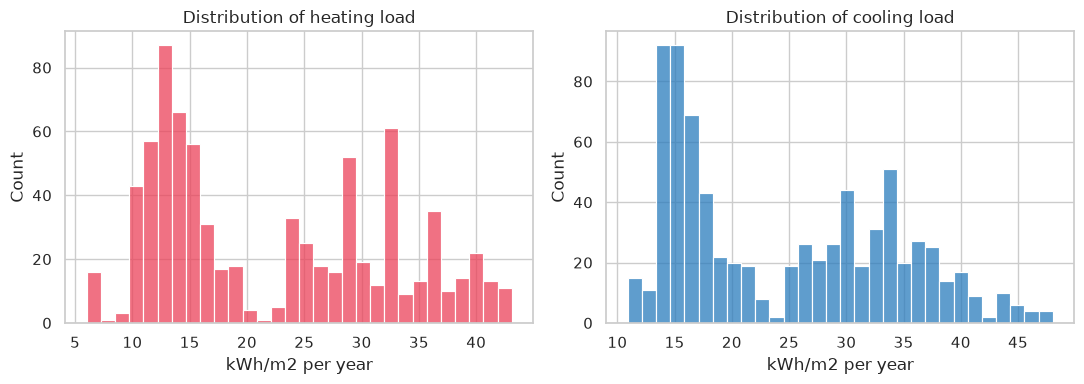

      heating_load  cooling_load
mean         22.31         24.59
std          10.09          9.51
min           6.01         10.90
max          43.10         48.03

Correlation between heating and cooling load: 0.976


In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, t, col in zip(axes, TARGETS, [HEAT, COOL]):
    sns.histplot(df[t], bins=30, color=col, ax=ax)
    ax.set_title(f"Distribution of {t.replace('_', ' ')}"); ax.set_xlabel("kWh/m2 per year")
save("01_target_distributions")
plt.show()
print(df[TARGETS].agg(["mean", "std", "min", "max"]).round(2))
print("\nCorrelation between heating and cooling load:", round(df.heating_load.corr(df.cooling_load), 3))

Both loads have a mean of about 22-25 and a standard deviation of about 10, and both show **two clusters** (a group of low-load buildings and a group of high-load ones). Heating and cooling load are almost perfectly correlated: a building that needs a lot of heating also needs a lot of cooling in this simulation.

### 3.1.4 What separates the clusters? Shape and height

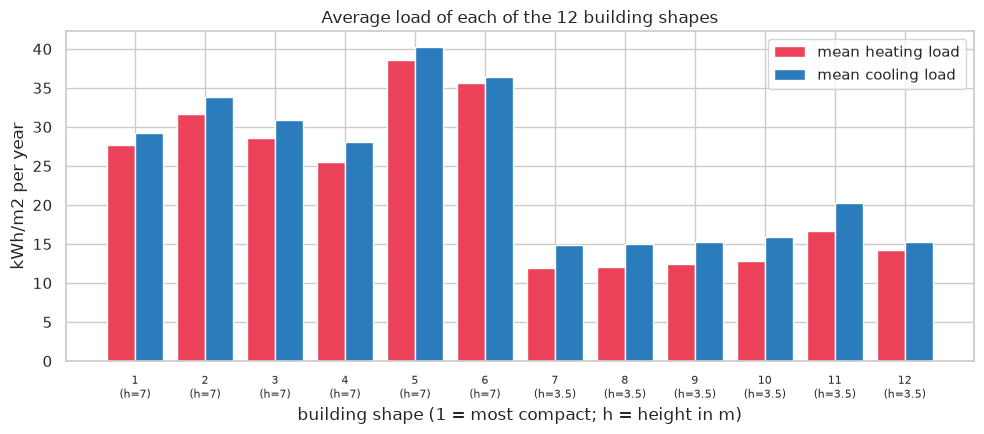

In [9]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(shapes)); w = 0.4
ax.bar(x - w/2, shapes.mean_heating, w, color=HEAT, label="mean heating load")
ax.bar(x + w/2, shapes.mean_cooling, w, color=COOL, label="mean cooling load")
ax.set_xticks(x); ax.set_xticklabels([f"{i}\n(h={h:g})" for i, h in zip(shapes.shape_id, shapes.overall_height)], fontsize=8)
ax.set_xlabel("building shape (1 = most compact; h = height in m)"); ax.set_ylabel("kWh/m2 per year")
ax.set_title("Average load of each of the 12 building shapes"); ax.legend()
save("02_load_by_shape")
plt.show()

In [10]:
print(df.groupby("overall_height")[TARGETS].agg(["mean", "std"]).round(1))

               heating_load      cooling_load     
                       mean  std         mean  std
overall_height                                    
3.5                    13.3  2.7         16.1  2.4
7.0                    31.3  6.0         33.1  5.5


**Finding:** the shape, and especially the **height**, has by far the biggest effect. Tall buildings (7 m) have an average heating load of 31.3 against 13.3 for low ones (3.5 m), and a cooling load of 33.1 against 16.1.

**A trap hidden in the shape table:** look at the heights of the 12 shapes. The **six most compact shapes (1 to 6) are all 7 m tall** and the **six least compact shapes (7 to 12) are all 3.5 m**. So in this dataset **compactness and height are completely tangled together**. The data will show that "more compact buildings use more energy" (a correlation of +0.62), but that is really the *height* effect in disguise: no model can separate the two with this data, so we must not interpret compactness on its own.

### 3.1.5 Do the other inputs matter?
For each of the other inputs we plot the **average load** at every setting, with the spread as a thin line.

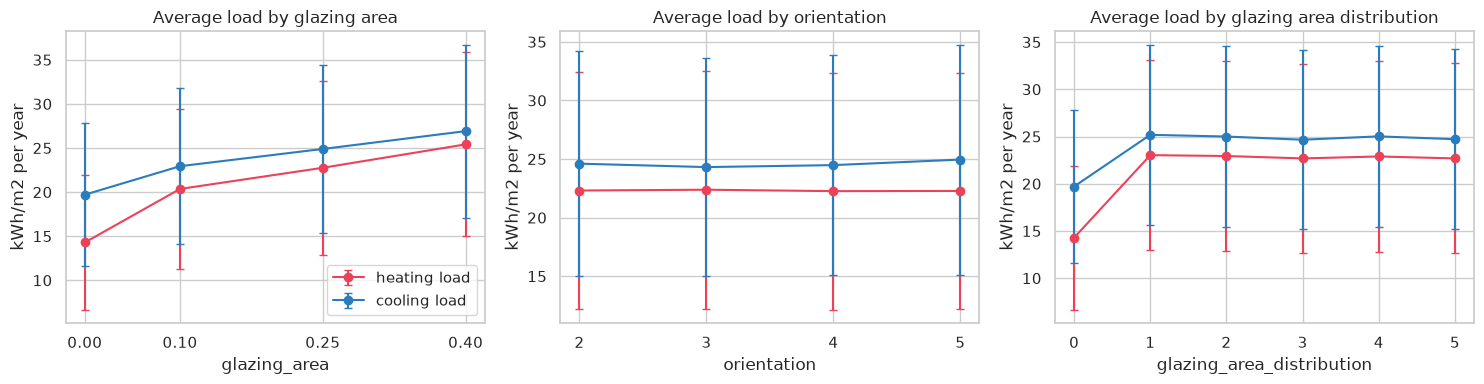

glazing_area
glazing_area  0.00  0.10  0.25  0.40
heating_load  14.3  20.4  22.8  25.4
cooling_load  19.7  22.9  24.9  26.9 

orientation
orientation      2     3     4     5
heating_load  22.3  22.4  22.3  22.3
cooling_load  24.6  24.3  24.5  25.0 

glazing_area_distribution
glazing_area_distribution     0     1     2     3     4     5
heating_load               14.3  23.0  22.9  22.7  22.9  22.7
cooling_load               19.7  25.2  25.0  24.7  25.0  24.7 



In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["glazing_area", "orientation", "glazing_area_distribution"]):
    for t, col in zip(TARGETS, [HEAT, COOL]):
        g = df.groupby(c)[t].agg(["mean", "std"])
        ax.errorbar(g.index, g["mean"], yerr=g["std"], marker="o", color=col, capsize=3, label=t.replace("_", " "))
    ax.set_title(f"Average load by {c.replace('_', ' ')}"); ax.set_xlabel(c); ax.set_ylabel("kWh/m2 per year")
    ax.set_xticks(sorted(df[c].unique()))
axes[0].legend()
save("03_effect_of_other_inputs")
plt.show()
for c in ["glazing_area", "orientation", "glazing_area_distribution"]:
    print(c); print(df.groupby(c)[TARGETS].mean().round(1).T.to_string(), "\n")

**Findings** (read these off the table and chart above):
* **Glazing area:** more window area goes with a higher load, for both heating and cooling.
* **Orientation:** the average load barely changes between the four orientations, so by itself it is a weak input.
* **Glazing distribution:** the averages differ only slightly between distribution types; the clear step is between "no windows" and "some windows".
* The thin lines are long: the spread within each setting is large because shape and height dominate. Orientation and windows only make small adjustments on top of the shape.

### 3.1.6 Correlations and multicollinearity
**Correlation** (-1 to +1) shows how two columns move together. We include the targets.

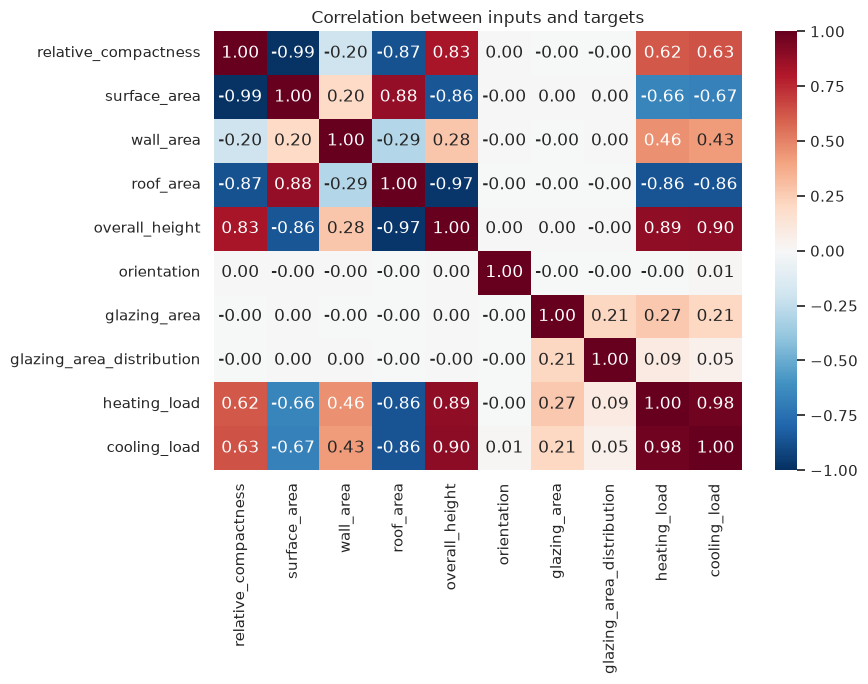

In [12]:
fig, ax = plt.subplots(figsize=(9, 7))
cm = df[inputs + TARGETS].corr()
sns.heatmap(cm, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation between inputs and targets")
save("04_correlation_heatmap")
plt.show()

In [13]:
# Some inputs may carry almost the same information ("multicollinearity"). Variance Inflation Factor (VIF) measures it:
# 1 = independent; above ~10 = strongly overlapping; infinity = one column is an exact copy of a combination of others.
def vif(frame):
    out = {}
    for c in frame.columns:
        others = frame.drop(columns=c)
        r2 = LinearRegression().fit(others, frame[c]).score(others, frame[c])
        out[c] = np.inf if r2 > 0.999999 else 1 / (1 - r2)
    return pd.Series(out)

numeric_inputs = ["relative_compactness", "surface_area", "wall_area", "roof_area", "overall_height", "glazing_area"]
print(vif(df[numeric_inputs]).round(1).to_string())
diff = (df.surface_area - (df.wall_area + 2 * df.roof_area)).abs().max()
print(f"\nLargest difference between surface_area and wall_area + 2 x roof_area: {diff:.6f}")

relative_compactness    105.5
surface_area              inf
wall_area                 inf
roof_area                 inf
overall_height           31.2
glazing_area              1.0

Largest difference between surface_area and wall_area + 2 x roof_area: 0.000000


**Key finding - multicollinearity.** The inputs overlap heavily. Relative compactness has a VIF of about 105 and overall height about 31, and the VIF of `surface_area`, `wall_area` and `roof_area` is **infinite**, because **surface area is exactly wall area + 2 x roof area** (the walls plus a roof and a floor of equal size). Any one of those three columns carries no new information given the other two. Only `glazing_area` (VIF 1.0) is independent of the rest.

**Why it matters:** *plain linear regression* can still make predictions, but the individual coefficients become unstable and hard to interpret. *Regularised* linear models (Ridge, Lasso) and *tree-based* models handle this much better, which is one reason we compare several algorithms in Notebook 2.

---
## 3.2 Data Cleaning
**What:** fixing problems in the raw data. **Why:** "garbage in, garbage out".

### 3.2.1 Missing values and duplicates
None of either (checked above), so nothing to remove or fill in.

### 3.2.2 Logical consistency checks

In [14]:
checks = {
    "surface_area != wall_area + 2 x roof_area": int(((df.surface_area - (df.wall_area + 2 * df.roof_area)).abs() > 1e-6).sum()),
    "glazing_area = 0 but glazing distribution not 0": int(((df.glazing_area == 0) & (df.glazing_area_distribution != 0)).sum()),
    "glazing_area > 0 but glazing distribution = 0": int(((df.glazing_area > 0) & (df.glazing_area_distribution == 0)).sum()),
    "negative areas, height or loads": int((df[["surface_area", "wall_area", "roof_area", "overall_height", *TARGETS]] < 0).any(axis=1).sum()),
    "glazing_area outside 0-1": int((~df.glazing_area.between(0, 1)).sum()),
}
pd.Series(checks, name="rows violating rule").to_frame()

,rows violating rule
surface_area != wall_area + 2 x roof_area,0
glazing_area = 0 but glazing distribution not 0,0
glazing_area > 0 but glazing distribution = 0,0
"negative areas, height or loads",0
glazing_area outside 0-1,0


Every rule passes with **0 violations**, so no rows need to be corrected or removed.

### 3.2.3 Outliers
An **outlier** is a value far from the rest. We apply the standard rule (more than 1.5 x IQR outside the middle 50%) to the targets.

In [15]:
out = []
for t in TARGETS:
    q1, q3 = df[t].quantile([0.25, 0.75]); iqr = q3 - q1
    n = int(((df[t] < q1 - 1.5 * iqr) | (df[t] > q3 + 1.5 * iqr)).sum())
    out.append({"target": t, "outliers": n, "percent": round(n / len(df) * 100, 1), "min": df[t].min(), "max": df[t].max()})
pd.DataFrame(out)

,target,outliers,percent,min,max
0,heating_load,0,0.0,6.01,43.10
1,cooling_load,0,0.0,10.90,48.03


**Decision:** nothing is flagged (0 outliers for both targets). The loads are simulation results for valid designs, so every value is legitimate. We keep all 768 buildings.

---
## 3.3 Feature Engineering
**What:** creating new, more useful columns and converting columns into a form models can use.

### 3.3.1 New features from simple geometry
Architects often describe a building by how much outside surface it has compared with the space inside. We can build three simple features from existing columns:
* `volume` = floor area x height. The floor area equals the roof area, so `volume = roof_area x overall_height`.
* `surface_to_volume` = surface area / volume.
* `glazing_m2` = window area in m² = `glazing_area` x floor area.

These add no new measurements. We try them and let the data tell us whether they help.

In [16]:
df["volume"] = df["roof_area"] * df["overall_height"]
df["surface_to_volume"] = df["surface_area"] / df["volume"]
df["glazing_m2"] = df["glazing_area"] * df["roof_area"]

new_feats = ["volume", "surface_to_volume", "glazing_m2"]
print(df[new_feats].describe().round(2).T)
print("\nCorrelation with the targets:")
print(df[new_feats + ["relative_compactness", "overall_height", "glazing_area"]].corrwith(df.heating_load).round(2).rename("with heating_load").to_frame()
      .join(df[new_feats + ["relative_compactness", "overall_height", "glazing_area"]].corrwith(df.cooling_load).round(2).rename("with cooling_load")))

                   count    mean     std     min     25%     50%     75%      max
volume             768.0  850.35  107.73  771.75  771.75  771.75  900.38  1029.00
surface_to_volume  768.0    0.81    0.17    0.57    0.65    0.83    0.96     1.05
glazing_m2         768.0   41.39   26.49    0.00   22.05   36.75   55.12    88.20

Correlation with the targets:
                      with heating_load  with cooling_load
volume                             0.66               0.68
surface_to_volume                 -0.78              -0.80
glazing_m2                        -0.12              -0.18
relative_compactness               0.62               0.63
overall_height                     0.89               0.90
glazing_area                       0.27               0.21


**What the correlations say:** `surface_to_volume` has a strong **negative** correlation with both loads (about -0.8): in this dataset the buildings with the *smallest* surface-to-volume ratio are the tall ones, and the tall ones have the highest loads per floor area. It is the height effect again, seen from another angle. `glazing_m2` is only weakly (even slightly negatively) correlated with the loads, because it mixes the window share with the roof area, which is smaller for tall buildings. The features may still help models, but their correlations with the loads should not be read as physical cause and effect.

### 3.3.2 Grouping the columns by type
* **Numeric** inputs (real quantities): the areas, compactness, height, glazing area and the three new features. These will be **scaled**.
* **Nominal categorical** inputs (codes that stand for labels, not quantities): `orientation` (2 to 5) and `glazing_area_distribution` (0 to 5). Code 5 is not "more" than code 2, so these will be **one-hot encoded** (one yes/no column per category).

In [17]:
nominal_cols = ["orientation", "glazing_area_distribution"]
numeric_cols = ["relative_compactness", "surface_area", "wall_area", "roof_area", "overall_height", "glazing_area",
                "volume", "surface_to_volume", "glazing_m2"]
print("numeric :", numeric_cols)
print("nominal :", nominal_cols)
print("total input features:", len(numeric_cols) + len(nominal_cols), "(8 original + 3 engineered, minus 0 removed)")

numeric : ['relative_compactness', 'surface_area', 'wall_area', 'roof_area', 'overall_height', 'glazing_area', 'volume', 'surface_to_volume', 'glazing_m2']
nominal : ['orientation', 'glazing_area_distribution']
total input features: 11 (8 original + 3 engineered, minus 0 removed)


### 3.3.3 Encoding and scaling
* **Scaling (standardisation)** rewrites each numeric column as "how many standard deviations from average" (mean 0, spread 1). Without it, a column measured in hundreds (surface area) would drown out one measured in fractions (glazing area) for models that rely on distances or gradients (linear models, SVR, k-NN, neural networks). Trees do not need it.
* **One-hot encoding** replaces a code column by one yes/no column per category.

> **Golden rule - prevent data leakage:** the scaler and encoder must learn their numbers from the **training data only**, and are then just *applied* to validation and test data. We therefore **split first, preprocess second**.

---
## 3.4 Data Splitting
We divide the buildings into three parts:

| Part | Share | Purpose (school analogy) |
|---|---|---|
| **Training set** | 70% | Practice exercises the model learns from |
| **Validation set** | 15% | Mock exam: compare models and tune settings |
| **Test set** | 15% | The real final exam, used **once** at the end |

Because the 12 shapes are the main driver of the loads, we make sure **every part contains every shape in the same proportion** (a *stratified* split, here stratified by `shape_id`). `random_state=42` makes the split repeatable.

> **Honest note.** Every shape appears in all three parts, so the test set measures "predicting a *known* shape with a new orientation/window combination". It does not measure "predicting a completely new shape". We will measure that separately in Notebooks 2 and 3.

In [18]:
X = df.drop(columns=TARGETS)
idx = np.arange(len(df))
train_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=df.shape_id, random_state=SEED)
val_idx, test_idx = train_test_split(tmp_idx, test_size=0.50, stratify=df.shape_id.iloc[tmp_idx], random_state=SEED)
parts = {"train": df.iloc[train_idx], "val": df.iloc[val_idx], "test": df.iloc[test_idx]}

summary = pd.DataFrame({
    "buildings": {k: len(v) for k, v in parts.items()},
    "mean heating": {k: v.heating_load.mean() for k, v in parts.items()},
    "std heating": {k: v.heating_load.std() for k, v in parts.items()},
    "mean cooling": {k: v.cooling_load.mean() for k, v in parts.items()},
    "std cooling": {k: v.cooling_load.std() for k, v in parts.items()}}).round(2)
display(summary)
display(pd.DataFrame({k: v.groupby("shape_id").size() for k, v in parts.items()}).T)

,buildings,mean heating,std heating,mean cooling,std cooling
train,537,22.35,10.10,24.60,9.52
val,115,22.49,10.09,24.67,9.46
test,116,21.91,10.12,24.47,9.61


shape_id,1,2,3,4,5,6,7,8,9,10,11,12
train,45,45,45,44,45,45,44,44,45,45,45,45
val,10,9,9,10,10,9,10,10,10,10,9,9
test,9,10,10,10,9,10,10,10,9,9,10,10


The three parts have almost identical load statistics, and every shape appears in each of them (about 45 / 10 / 10 buildings per shape in train / validation / test).

### Building and testing the preprocessing recipe
A `ColumnTransformer` applies the right treatment to each group of columns. We **fit it on the training set only**.

In [19]:
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), numeric_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), nominal_cols),
])
feature_cols = numeric_cols + nominal_cols
Xtr = preprocessor.fit_transform(parts["train"][feature_cols])     # learn from TRAIN and transform it
Xva = preprocessor.transform(parts["val"][feature_cols])           # only transform (no learning!)
Xte = preprocessor.transform(parts["test"][feature_cols])
print("Before:", len(feature_cols), "columns  |  After one-hot encoding:", Xtr.shape[1], "columns")
print("Shapes (train / val / test):", Xtr.shape, Xva.shape, Xte.shape)
print("\nScaled numeric columns on TRAIN (mean should be ~0, std ~1):")
pd.DataFrame(Xtr[:, :len(numeric_cols)], columns=numeric_cols).agg(["mean", "std"]).round(2).T

Before: 11 columns  |  After one-hot encoding: 19 columns
Shapes (train / val / test): (537, 19) (115, 19) (116, 19)

Scaled numeric columns on TRAIN (mean should be ~0, std ~1):


,mean,std
relative_compactness,-0.0,1.0
surface_area,-0.0,1.0
wall_area,0.0,1.0
roof_area,0.0,1.0
overall_height,-0.0,1.0
glazing_area,-0.0,1.0
volume,-0.0,1.0
surface_to_volume,0.0,1.0
glazing_m2,0.0,1.0


Training means are about 0 and standard deviations about 1, as designed. (Validation and test will be *close to* but not exactly 0 and 1. That is correct, because they were scaled with the *training* numbers.)

### Saving everything for the next notebooks

In [20]:
import joblib
out_dir = DATA / "splits"; out_dir.mkdir(exist_ok=True)
for name, part in parts.items():
    part.to_csv(out_dir / f"{name}.csv", index=False)           # includes shape_id and both targets
json.dump({"numeric": numeric_cols, "nominal": nominal_cols, "targets": TARGETS, "geometry": geom},
          open(out_dir / "feature_groups.json", "w"), indent=2)
shapes.to_csv(out_dir / "shape_table.csv", index=False)
print("Saved:", sorted(p.name for p in out_dir.iterdir()))

Saved: ['feature_groups.json', 'shape_table.csv', 'test.csv', 'train.csv', 'val.csv']


---
# Summary of Notebook 1

| Step | What we did | Key result |
|---|---|---|
| Problem definition | Regression for two targets (heating and cooling load) | Targets: R² >= 0.95 and RMSE <= 2.0 for both |
| Data collection | UCI Energy Efficiency (768 simulated buildings, 8 inputs) | A designed grid: 12 shapes x 4 orientations x 16 window options |
| EDA | Distributions, shape and input effects, correlations | Shape/height dominate (compactness and height are tangled); more glazing raises loads; orientation is weak; heating and cooling are 0.98 correlated |
| Multicollinearity | VIF and an exact identity | surface area = wall area + 2 x roof area |
| Cleaning | Missing, duplicates, logic checks, outliers | Data is clean; nothing removed |
| Feature engineering | 3 physical features; one-hot encoding; scaling | 11 input columns become 19 after encoding |
| Splitting | 70/15/15 stratified by shape | 537 / 115 / 116 buildings; preprocessing fitted on train only |

**Next (Notebook 2):** choose algorithms, train a baseline, compare models, check overfitting, run the "unseen shapes" stress test and tune the best models.

---
# Glossary
* **Regression:** predicting a number. **Classification:** predicting a category.
* **Feature (X) / target (y):** an input column / the number we want to predict.
* **MAE, MSE, RMSE, R²:** error measures for regression (see Step 1).
* **Multicollinearity:** inputs that carry (almost) the same information.
* **VIF:** a number measuring multicollinearity (above ~10 is a warning; infinity = an exact copy).
* **One-hot encoding:** turning a category column into several yes/no columns.
* **Scaling / standardisation:** rewriting numbers to a common scale (mean 0, spread 1).
* **Data leakage:** accidentally letting information from validation/test data influence training.
* **Stratified split:** a split that keeps the mix of a chosen group (here, building shapes) the same in every part.
* **Simulated data:** values produced by a computer program rather than measured in real buildings.